In [ ]:
!lscpu

Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             46 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      2
  On-line CPU(s) list:       0,1
Vendor ID:                   GenuineIntel
  Model name:                Intel(R) Xeon(R) CPU @ 2.20GHz
    CPU family:              6
    Model:                   79
    Thread(s) per core:      2
    Core(s) per socket:      1
    Socket(s):               1
    Stepping:                0
    BogoMIPS:                4399.99
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ss h
                             t syscall nx pdpe1gb rdtscp lm constant_tsc rep_goo
                             d nopl xtopology nonstop_tsc cpuid tsc_known_freq p
                             ni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2ap
                   

## Include boost multiprecision and benchmark libraries

In [ ]:
!sudo apt-get update -y
!sudo apt-get install libboost-all-dev -y

Get:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Hit:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:3 https://cli.github.com/packages stable InRelease
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:5 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:7 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Get:9 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:12 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [2,812 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [9,374 kB]
Get:14 http://security.ubu

In [ ]:
!git clone https://github.com/google/benchmark.git
!git clone https://github.com/google/googletest.git benchmark/googletest

Cloning into 'benchmark'...
remote: Enumerating objects: 9891, done.
remote: Counting objects: 100% (229/229), done.
remote: Compressing objects: 100% (113/113), done.
remote: Total 9891 (delta 173), reused 115 (delta 115), pack-reused 9662 (from 3)
Receiving objects: 100% (9891/9891), 3.19 MiB | 14.20 MiB/s, done.
Resolving deltas: 100% (6634/6634), done.
Cloning into 'benchmark/googletest'...
remote: Enumerating objects: 28346, done.
remote: Counting objects: 100% (157/157), done.
remote: Compressing objects: 100% (117/117), done.
remote: Total 28346 (delta 86), reused 44 (delta 39), pack-reused 28189 (from 4)
Receiving objects: 100% (28346/28346), 13.56 MiB | 17.87 MiB/s, done.
Resolving deltas: 100% (21026/21026), done.


In [ ]:
!rm -rf benchmark/build
!cmake -E make_directory "benchmark/build"
!cmake -E chdir "benchmark/build" cmake -DCMAKE_BUILD_TYPE=Release ..
!cmake --build "benchmark/build" --config Release --target install

-- The CXX compiler identification is GNU 11.4.0
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /usr/bin/c++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- Failed to find LLVM FileCheck
-- Found Git: /usr/bin/git (found version "2.34.1")
-- Google Benchmark version: v1.9.4-60-gd029e781, normalized to 1.9.4.60
-- Looking for shm_open in rt
-- Looking for shm_open in rt - found
-- Performing Test HAVE_CXX_FLAG_WALL
-- Performing Test HAVE_CXX_FLAG_WALL - Success
-- Performing Test HAVE_CXX_FLAG_WEXTRA
-- Performing Test HAVE_CXX_FLAG_WEXTRA - Success
-- Performing Test HAVE_CXX_FLAG_WSHADOW
-- Performing Test HAVE_CXX_FLAG_WSHADOW - Success
-- Performing Test HAVE_CXX_FLAG_WFLOAT_EQUAL
-- Performing Test HAVE_CXX_FLAG_WFLOAT_EQUAL - Success
-- Performing Test HAVE_CXX_FLAG_WOLD_STYLE_CAST
-- Performing Test HAVE_CXX_FLAG_WOLD_STYLE_CAST - Success
-- Performing Test HAVE_CXX_FLAG_WCON

## Algorithm implementation

In [ ]:
%%writefile prog.cpp
#include <boost/multiprecision/cpp_int.hpp>
#include <boost/random.hpp>
#include <iostream>

using namespace boost::multiprecision;
using namespace boost::multiprecision::literals;
using namespace boost::random;

using uint512 = number<cpp_int_backend<512, 512, unsigned_magnitude, unchecked, void>>;
using uint1024 = number<cpp_int_backend<1024, 1024, unsigned_magnitude, unchecked, void>>;

// Computes (a^p) % n while also checking for compositeness
uint512 power(uint512 a, uint512 p, uint512 n, bool *isProbablyPrime) {
  if (p == 0)
    return 1;

  // Recursive call: compute a^(p/2) % n
  uint512 x = power(a, p/2, n, isProbablyPrime);
  uint512 result = uint512((uint1024(x) * uint1024(x)) % uint1024(n));

  // If we find a nontrivial square root of 1 modulo n, n is composite
  if (result == 1 && x != 1 && x != n-1 )
    *isProbablyPrime = false;

  // If the exponent is odd, multiply by a and reduce modulo n
  if (p % 2 == 1)
    result = uint512((uint1024(a) * result) % uint1024(n));

  return result;
}

// Function: probabilistic primality test using Fermat-like check
bool primalityTest(uint512 n) {
  mt19937 mt(clock());

  // Generate a random base 'a' in the range [2, n-1]
  uniform_int_distribution<uint512> ui(uint512(2), n-1);
  uint512 a = ui(mt);

  bool isProbablyPrime = true;

  uint512 result = power(a, n-1, n, &isProbablyPrime);
  if (result != 1 || !isProbablyPrime)
    return false;
  else
    return true;
}


Writing prog.cpp


## Testing

### Testing 512 bit prime numbers

In [ ]:
%%writefile test.cpp
#include <boost/multiprecision/cpp_int.hpp>
#include "prog.cpp"

using namespace boost::multiprecision;
using namespace boost::multiprecision::literals;
using uint512 = number<cpp_int_backend<512, 512, unsigned_magnitude, unchecked, void>>;

// List of known large prime numbers to test
uint512 primes[] = {
	0xF7F97C05E567868D0B751CF23B59184599BDD4A3D7F1D73851AD2B39C4FD2869EDE7C57DE85F3546457C5955F032BE7221D2A55DDCBBC9D423BCF75A4097A17F_cppui512,
	0x901F228A5D67F9204CDBE196D4B744FA0B8636264D334E46DDF5A9596DF774F31B111321CF3AC84A00EB5E8F5941BEF5FB4C3305BE6BBC79EC0577D0A0DF1B13_cppui512,
	0xF6B8C1F8E24045C33F1BDA12946D6DE3D419A7D871D78BD24FBF21B480B2F09F510D0B48C212947A93008945707D7ACB63E8A69BF8AE7F52B61CCC580B3BFC2F_cppui512,
	0xE377AD2AC3CB5B27DE38276D45E8475E8D2EF8907250EE0196AD81BB1A74414A32D5D2FF1AA4399A351C7AB67568C53F6E6D781C47C730F717991FABB02E186D_cppui512,
	0xBC74C68E78FCACC0BA33DEBB79F2C73C0BA96C87E2B24FBE9589D95D0A76BD051EC263FC9EBC471AF801F8400B561682795F05B7145BBBFF04417DA0D980C8E3_cppui512,
	0x90D0C76FD353397C53C637578CD94CDCCDC4AB7E335D33638951FA17B2C85406F900FC52F7B1E4E25927DFD955CE3B5758ABD1FB60AAEF555B8C0FBCF114047B_cppui512,
	0xA841704C7FC6BA20C50C760BBD1C97ACEC650FCCC8A9A8D651076B54816A0D7A2519CC698305FA4FB6EF7B72933487190B6CF3EDC6D7DA5E12FBCAA25FA3261D_cppui512,
	0xF5DAB7CD1A0B48E85DC798908D7130D6B48D49750A4898C196BC62403991BB5E7957F99D70158185088EFC52439A6DAE662C84FA40C4FCACD8CF78555BC0AEB9_cppui512,
	0xFC92990C4AC4D9E5DFA39480C7A2D30710221A777CA53072D0BAB8C04CCC00F0EB17E1069401CFA7625E3B10F032F3000FF2B3C44D4B76594AE016CC395FB093_cppui512,
	0xD66333C345A6DC9D3DB58CB4E123D412F04A14DC7C2D3A0231ED49EB917A64A47705FD9C52D592AA465E01940F8BBAFF4475CE48ADE41228368EAE651E2650B9_cppui512,
	0x9E6F574B3EA32C422CDF99BEA5F864553D253DC2E4DA77EE008AC7E2F66E6ACF575E52044D7E3353BF18E1752CC0589C2FE1B829FD0A67429B0A6E9E4483C511_cppui512,
	0x8921B542D5F72F527B2455F683E4939C45634C10C3AA26C679E48884B24ABE4C12526A5681FFE4FCBA487CD956981A1C550F3A103C3DCC68E110AF0FE2A1F45F_cppui512,
	0xDD2960F486326FC1A2AC4FC7924C3B331FC5C0283C3739F7D71689A78F7A42542A6197B7CC5BC7CE7B5331247624493BAB4A1BD24FFD1AEF7C9AD399AC809239_cppui512,
	0x8FCA96A00D92D0EA48E6902C195741DDF93CC9E8C21556B177BC5A419C843AA08CD7C9AD34B559CC41999578812755098F16F3F92562210D9D176EAECA414879_cppui512,
	0x82994D2ABB3CB8DDAFB532E9ADA52D2C69A66126E7E0FE2982B76469128DE1B5BEDF0E3062B45293EF67164CAC616C8E308E3EE1CBA9EF09C14D820F7CA75675_cppui512,
	0x9E74DD73CC8F180AA8F31E4676F16BEE7B4319A127A90B74301F9A39D14739D667E5356819EA28E6BA4C7C6DC9DDCC625A1BAAB2D072C45BFE588765EC64E2CF_cppui512,
	0xE884300387D8554D7D22CB8ACD94697A8C26CFC83447C4291965A551CE64C2A3E3D9AB8F7A70BFE5E19946282460D62CA10B5D311E3F574958D6E7AF8FA7DA11_cppui512,
	0xAAE2397BF59FBD3140C2DC02531658E1340B3B3B33B577BB80483B891038C440D24974285CD174E2AFAA2F2B360B7B79B0E0EDA0770EED8FB5CCED1BA3D891D9_cppui512,
	0x8792A51D21FC85C31930A21E2EF354592DC69D7B2795425814C2522C2767289F3FFCE8451486CB95BF3B544DF1DDF44CC54DA48B40391110B933D7D5E90639FF_cppui512,
	0xE7E9212A41F622F8C1CBAB96C35603C205B4C607D684CD94B44E037AC7F80DD3AF4F9C4DFA4DBEC34C1F8F130AD86F95A49834254C84D84FBBBB8F4DC217C62D_cppui512,
	0xD6428193F6BEEB37E36CEF407EEAE5241ECAC1730866EA2BD27FC28E774FE78ECF0876F4B1CF6E2977A032676C81A3F5268E485D7327B0EF5203C961AF5EEB35_cppui512,
	0xED96CF96AD0576AC9A8D4C14D0390E7F71882CF1C098DE7D0B9F4A5FB9041ADC68E778B96754EF161678CA30D2606C2166B378E29C071C21986DC361BB618249_cppui512,
	0xB3150F577162D467B075CBDD098BBD7CFAB7AFB619BE9757BECFC398E79076451F065793A77B09AD8238C55ECAB0E518D44995500B0B630B3DC7157CC2D8DABB_cppui512,
	0xCAFB81C419D046E9ACB4FECB18761EBABCA24AB7F802B4931BFAF0B5CAFDBB06019C3487CBA1309BFB6ED8A619E002E75183C948E761268A9262547655996D85_cppui512,
	0xA0F98EF0487F9223C33CACCFEBB13FF5FFBCC90CE62F651B607C40619FCA630292BCEB56D52D1781281E0E6503DF7464220BE0F1C5593130CF24500B51394E21_cppui512,
	0xF2BA7B28CFDE8E790DDE8D0FFFE7A0CA7F82FEFDE86E98F4DB0F50D431FA801140ADC7C8118CB5D205B34BB5940B9621B7FED6241C1C207A7F90554F52C0A9BD_cppui512,
	0x9A9C8CDB2B235404579FC5F1697E2E3A39856B8EDFB768B937B384F193C57384027C07797FBFB24FA854FD59C9B38ABEA6672F999E0E7D097D341186F9C73857_cppui512,
	0x9289F387B9704FD362B87D917AB435F4AE5B5190B616FD477844180C559D8E37486BBC3EC16370AC46781BBA36E391722A16391BBCB20CC3B8DFF843E7AD354B_cppui512,
	0xDB00258C6B9BFFF479E5A0611480F67A6FC82B46A4A7DE8BA098E36D18324A3632F9787A2D292969098AB2398B1AA0E164EA86D021B411979C8521215FAE50ED_cppui512,
	0xC0E4703EF897039D29213840A4395C91A4812C6C244A136CDDDE825407543DF57FAD8DA3152863EEB77C32C4325CA2CF926DEB5F1C0399FD3DABF76EF33FE96B_cppui512,
	0xD7A3BF2307B6729AA93D0AEB81A4BC08786917B1CA4A68649671D30DC48641B16066393524C0C482470B52EE186413C50884C303C1A9FEC38043C2718CDB8BA5_cppui512,
	0xB90DEF0654820439804FE900090A9A630ADB564FAA5AFC1AE3066494CC41138F840B4CB2BC2D877D572ECCBE0E611B12AEC7B2025F153CC69346C15AD0DA1501_cppui512,
	0xEABACEC4D674BDADD775DD1E3CF307B674D9B6BC00403AD447C003B9128D07F969BABD8C9B784A6CF1D740A1449DF59DF95FB4B7CFD66A33FD64877F1AF7DDF1_cppui512,
	0xE742E1F7FC29998E61080E95CD6D8FF320DC530DFD8EC53077F38AED0E891C715782E9A962501DCE633542BA5307AE73E962144C42BC53E23BC4D4E027EC71BF_cppui512,
};

int main() {

  for (uint512 prime : primes) {
    bool isComposite = false;

    std::cout << "Chosen num: " << prime << std::endl;

		// Run the probabilistic primality test multiple times (25 iterations)
    for (int i = 0; i < 25; i++) {
      if (!primalityTest(prime)) {
        std::cout << "The prime num above was recognized as composite after " << i+1 << " tries !!!" << std::endl;
        isComposite = true;
        break;
      }
    }

    if(!isComposite)
      std::cout << "The num above is probably prime" << std::endl;
    }

  return 0;
}

Writing test.cpp


In [ ]:
!g++ test.cpp -o test
!./test

Chosen num: 12987480938933093342045251083642243926496817250592797580486918701850491917937644094034717498186635708262056392855225677084842227196584163856546029312123263
The num above is probably prime
Chosen num: 7548261758535216920587480600159554300872334951974043496927404520033269353047585822914241332192319848564007956267867657209708218788915381623658739134307091
The num above is probably prime
Chosen num: 12921864440975014728223769224176970895191845214505001279875061948776889421170705140028815218399204602447336675713304009941012837655900417501215275695733807
The num above is probably prime
Chosen num: 11913438920025831422790308300577522257066396299027098064089469235571160795184628451138456118529433198688201758963855482804202347119456668554313888921688173
The num above is probably prime
Chosen num: 9870249710413009906511555099070293320870020676085947368503053126557855355312048531187319375039317493046045298895501389530833117631526418683258988119771363
The num above is probably prime
Ch

### Primality test random 512 bit numbers and compare against boost:PrimalityTest library (which uses miller_rabin test)

In [ ]:
%%writefile test2.cpp
#include <string.h>
#include <boost/multiprecision/cpp_int.hpp>
#include <boost/multiprecision/miller_rabin.hpp>
#include <boost/random.hpp>
#include "prog.cpp"

using namespace boost::multiprecision;
using namespace boost::multiprecision::literals;
using uint512 = number<cpp_int_backend<512, 512, unsigned_magnitude, unchecked, void>>;
using uint1024 = number<cpp_int_backend<1024, 1024, unsigned_magnitude, unchecked, void>>;
using namespace boost::random;

// Struct to store results of primality tests for a number
struct Result {
  uint512 num;
  bool isPrime;
  float correctness[4];
};

int main() {

  const int numbers_to_generate = 100;
  const int tries_per_num = 2000;
  Result results[numbers_to_generate];

  // Loop over each random number
  for(int i = 0; i < numbers_to_generate; i++) {
    bool isPrime_tries_1 = 1;
    bool isPrime_tries_5 = 1;
    bool isPrime_tries_10 = 1;
    bool isPrime_tries_25 = 1;

    // Gen number
    mt19937 mt2(clock());
    mt19937 mt3(clock());

    uniform_int_distribution<long> ui(2, 10000);

    uint512 randomNum = uint512(ui(mt2));

    // Result given by Boost library with 0.25^25 probability of error
    bool Boost_PrimalityTest = miller_rabin_test(randomNum, 25, mt3);


    int tries_per_confidence[tries_per_num][4];
    float mean_per_confidence[4];

    // Repeat testing to get statistical confidence
    for(int k = 0; k < tries_per_num; k++) {

      isPrime_tries_1 = primalityTest(randomNum);

      for(int j = 0; j < 5; j++) {
        if (!primalityTest(randomNum)) {
          isPrime_tries_5 = false;
          break;
        }
      }

      for(int j = 0; j < 10; j++) {
        if (!primalityTest(randomNum)) {
          isPrime_tries_10 = false;
          break;
        }
      }

      for(int j = 0; j < 25; j++) {
        if (!primalityTest(randomNum)) {
          isPrime_tries_25 = false;
          break;
        }
      }

      // Compare results with Boost's Miller-Rabin test and store 1 if they match, 0 otherwise
      tries_per_confidence[k][0] = isPrime_tries_1 == Boost_PrimalityTest ? 1 : 0;
      tries_per_confidence[k][1] = isPrime_tries_5 == Boost_PrimalityTest ? 1 : 0;
      tries_per_confidence[k][2] = isPrime_tries_10 == Boost_PrimalityTest ? 1 : 0;
      tries_per_confidence[k][3] = isPrime_tries_25 == Boost_PrimalityTest ? 1 : 0;
    }


    // Calculate mean correctness for each confidence level
    for(int j = 0; j < 4; j++) {
      mean_per_confidence[j] = 0.f;
      for(int k = 0; k < tries_per_num; k++) {
        mean_per_confidence[j] += float(tries_per_confidence[k][j]);
      }
      mean_per_confidence[j] /= float(tries_per_num);
    }

    results[i].num = randomNum;
    results[i].isPrime = Boost_PrimalityTest;
    for(int j=0; j<4; j++)
      results[i].correctness[j] = mean_per_confidence[j];

    if (i % 10 == 0) {
      printf("iteration %3d/%d\n", i, numbers_to_generate);
    }
  }

  // Print results for all numbers
  std::cout << std::endl;
  std::cout << "number   | prime | 1 try | 5 tries | 10 tries | 25 tries" << std::endl;
  std::cout << "---------------------------------------------------------" << std::endl;
  for(int i = 0; i < numbers_to_generate; i++) {
    Result r = results[i];
    std::string num = boost::lexical_cast<std::string>(r.num);
    printf("%-8s |   %1d   | %.3f | %.3f   | %.3f    | %.3f   \n",
      num.c_str(), r.isPrime, r.correctness[0], r.correctness[1], r.correctness[2], r.correctness[3]);
  }
}

Writing test2.cpp


In [ ]:
!g++ test2.cpp -o test2
!./test2

iteration   0/100
iteration  10/100
iteration  20/100
iteration  30/100
iteration  40/100
iteration  50/100
iteration  60/100
iteration  70/100
iteration  80/100
iteration  90/100

number   | prime | 1 try | 5 tries | 10 tries | 25 tries
---------------------------------------------------------
2045     |   0   | 0.998 | 1.000   | 1.000    | 1.000   
6131     |   1   | 1.000 | 1.000   | 1.000    | 1.000   
6539     |   0   | 1.000 | 1.000   | 1.000    | 1.000   
6854     |   0   | 0.999 | 1.000   | 1.000    | 1.000   
5991     |   0   | 0.999 | 1.000   | 1.000    | 1.000   
6140     |   0   | 1.000 | 1.000   | 1.000    | 1.000   
2598     |   0   | 1.000 | 1.000   | 1.000    | 1.000   
9606     |   0   | 1.000 | 1.000   | 1.000    | 1.000   
5747     |   0   | 1.000 | 1.000   | 1.000    | 1.000   
4824     |   0   | 1.000 | 1.000   | 1.000    | 1.000   
8657     |   0   | 0.999 | 1.000   | 1.000    | 1.000   
2366     |   0   | 1.000 | 1.000   | 1.000    | 1.000   
4234     |   0   | 0

## Benchmark

In [ ]:
%%writefile benchmark.cpp
#include <boost/multiprecision/cpp_int.hpp>
#include <benchmark/benchmark.h>
#include "prog.cpp"

using namespace boost::multiprecision;
using namespace boost::multiprecision::literals;
using uint512 = number<cpp_int_backend<512, 512, unsigned_magnitude, unchecked, void>>;

// Benchmark function to test performance of primalityTest
static void BM_NotPrimes(benchmark::State& state) {
    long exp = state.range(0);
    uint512 n = 1;
    n <<= exp;

    for (auto _ :state)
        benchmark::DoNotOptimize(primalityTest(n));
    state.SetComplexityN(exp);
}

BENCHMARK(BM_NotPrimes)
    ->DenseRange(8, 504, 8)
    ->Complexity();

BENCHMARK_MAIN();

Writing benchmark.cpp


In [ ]:
# !/bin/bash

BENCHMARK_OUT="benchmark.out.json"
BENCHMARK_OUT_FORMAT="json"
BENCHMARK_ENABLE_RANDOM_INTERLEAVING=1
BENCHMARK_REPETITIONS=5
!g++ benchmark.cpp -O2 -std=c++11 -isystem benchmark/include -Lbenchmark/build/src -lbenchmark -lpthread -o test
!./test \
--benchmark_time_unit=us \
--benchmark_enable_random_interleaving=$BENCHMARK_ENABLE_RANDOM_INTERLEAVING \
--benchmark_repetitions=$BENCHMARK_REPETITIONS \
--benchmark_out_format=$BENCHMARK_OUT_FORMAT \
--benchmark_out=$BENCHMARK_OUT

2025-10-18T15:17:43+00:00
Running ./test
Run on (2 X 2200 MHz CPU s)
CPU Caches:
  L1 Data 32 KiB (x1)
  L1 Instruction 32 KiB (x1)
  L2 Unified 256 KiB (x1)
  L3 Unified 56320 KiB (x1)
Load Average: 1.42, 1.21, 0.61
------------------------------------------------------------------
Benchmark                        Time             CPU   Iterations
------------------------------------------------------------------
BM_NotPrimes/104              47.5 us         47.4 us        14966
BM_NotPrimes/104              46.6 us         46.5 us        14966
BM_NotPrimes/104              46.3 us         46.2 us        14966
BM_NotPrimes/104              46.8 us         46.7 us        14966
BM_NotPrimes/104              45.3 us         45.3 us        14966
BM_NotPrimes/104_mean         46.5 us         46.4 us            5
BM_NotPrimes/104_median       46.6 us         46.5 us            5
BM_NotPrimes/104_stddev      0.810 us        0.777 us            5
BM_NotPrimes/104_cv           1.74 %          

## Plot of benchmark results

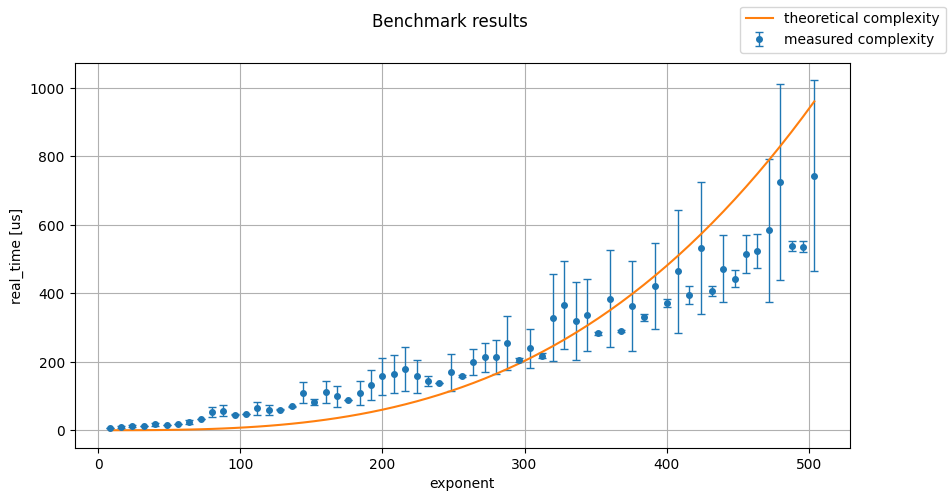

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
import json

def mean_string(value: str):
  return value['name'].endswith("mean")

def stddev_string(value: str):
  return value['name'].endswith("stddev")

def sort_mean_data(data):
  return int(data['name'][13:-5])

def sort_stddev_data(data):
  return int(data['name'][13:-7])

try:
  with open('benchmark.out.json', 'r') as file:
    data = json.load(file)['benchmarks']
    mean = [d for d in filter(mean_string, data)]
    stddev = [d for d in filter(stddev_string, data)]
    mean.sort(key=sort_mean_data)
    stddev.sort(key=sort_stddev_data)
    x = [int(d['name'][13:-5]) for d in mean]
    w = [0.0000075 * i**3 for i in x]
    y = [int(d['real_time']) for d in mean]
    yerr = [int(d['real_time']) for d in stddev]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.errorbar(x, y, yerr, label='measured complexity', fmt='o', linewidth=1, capsize=3, markersize=4)
    ax.plot(x, w, label='theoretical complexity')
    ax.set_xlabel('exponent')
    ax.set_ylabel('real_time [us]')
    ax.grid(True)
    fig.legend()
    fig.suptitle('Benchmark results')
    plt.show()

except json.JSONDecodeError:
    print("Error: Failed to decode JSON from the file.")
